# Modelado Predictivo: Clasificación con Gradient Boosting
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI)

**Contexto:** Este notebook desarrolla y evalúa un clasificador multiclase de Gradient Boosting, implementado desde cero con apoyo del curso Machine_Learning_desde_Cero-11 del Prof. Zucco. 

El modelo construye un ensamble de árboles de regresión de manera secuencial. En cada etapa, los nuevos árboles buscan corregir los errores que permanecen en las predicciones anteriores, ajustándose progresivamente a los patrones del conjunto de datos. Para este problema se utiliza la función de pérdida de entropía cruzada multiclase con activación Softmax.

### Objetivos del Modelado

1. **Entrenamiento del Modelo:** Ajustar los hiperparámetros principales (learning_rate, n_estimators y max_depth) para construir el ensamble.

2. **Evolución del aprendizaje:** Analizar el comportamiento de la exactitud y del Macro F1-Score conforme se agregan etapas mediante staged_predict, con el fin de observar la estabilidad del modelo.

3. **Evaluación del desempeño:** Examinar la Matriz de Confusión y las métricas de Precisión, Recall y F1-Score para cada categoría de salud fetal, prestando especial atención a la detección de casos sospechosos y patológicos.

### Ficha Metodológica del Modelo

* **Descripción breve del método:** Gradient Boosting combina árboles de regresión pequeños (max_depth=3) que se entrenan uno después de otro. Se configuraron 100 etapas (n_estimators=100) y una tasa de aprendizaje de 0.1. Cada etapa intenta corregir parte de los errores de las predicciones anteriores.

* **Justificación de su uso:** Se seleccionó por su capacidad para aprender patrones complejos en datos tabulares y refinar gradualmente sus predicciones. Debido al desbalance del conjunto de datos (77.85% de registros normales frente a 8.28% patológicos), se incorporó una ponderación de clases (balanced=True) para dar mayor importancia a las categorías con menos registros.

* **Métricas de evaluación utilizadas:** Se consideran la Exactitud Global (Accuracy), la evolución por etapas con staged_predict, la Precisión, el Recall y el F1-Score por clase, el promedio Macro F1-Score y la Matriz de Confusión.

* **Análisis de resultados:** Detallado en la conclusión final, destacando que el balanceo de clases elevó el **Recall en casos Patológicos a 94.29%** (con **F1-Score de 88.00%**) y en **Sospechosos a 84.75%**, manteniendo una **Precisión del 97.41%** al diagnosticar fetos Normales..

In [1]:
# Importación de librerías 

import os # Gestión de Carpetas
import sys # Config del sistema
import numpy as np # Matemáticas
import pandas as pd # Tablas
import matplotlib.pyplot as plt # Grafico
import time # Medición de Tiempos

# Modificación para importar los módulos fuera de la carpeta actual

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

# Importamos el clasificador Gradient Boosting y nuestras utilidades

from src.GradientBoosting import GradientBoostingClassifier
from src.utils_and_metrics import train_test_split, accuracy, confusion_matrix, precision, recall, f1_score, roc

In [2]:
# Carga directa de matrices X & y generadas en 02_EDA_Visualizacion
X_df = pd.read_csv('../data/processed/X_features.csv')
y_df = pd.read_csv('../data/processed/y_target.csv')

X = X_df.to_numpy()
y = y_df['NSP'].to_numpy().ravel().astype(int)

# Partición de datos (80% entrenamiento, 20% prueba) con seed=42 para comparación directa con Random Forest
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, seed=42)

# Visualización de control
display(X_df.head())
print(f"Dimensión de Matriz X (Características): {X.shape}")
print(f"Dimensión de Vector y (Objetivo NSP):    {y.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Clases en y:   {np.unique(y)}")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


Dimensión de Matriz X (Características): (2126, 21)
Dimensión de Vector y (Objetivo NSP):    (2126,)
Entrenamiento: X_train=(1701, 21), y_train=(1701,)
Prueba:        X_test=(425, 21), y_test=(425,)
Clases en y:   [1 2 3]


#### **Entrenamiento de (`GradientBoosting`)**

In [3]:
# Configuración de hiperparámetros del modelo
n_estimators = 100   # Número de etapas secuenciales de boosting
learning_rate = 0.1  # Tasa de aprendizaje (shrinkage)
max_depth = 3        # Árboles cortos para evitar sobreajuste

gb_model = GradientBoostingClassifier(
    n_estimators=n_estimators,
    learning_rate=learning_rate,
    max_depth=max_depth,
    balanced=True
)
t0 = time.perf_counter()

gb_model.fit(X_train, y_train)

tiempo_train_gb = time.perf_counter() - t0

# Evaluación sobre el conjunto de entrenamiento
train_preds = gb_model.predict(X_train)
train_accuracy = accuracy(y_train, train_preds)

print("\n--Resultados de Rendimiento en Entrenamiento--")
print(f"Etapas entrenadas (n_estimators):   {len(gb_model.trees_)} etapas ({len(gb_model.trees_) * gb_model.n_classes_} árboles en total)")
print(f"Accuracy:  {train_accuracy * 100:.2f}%")
print(f"Tiempo de entrenamiento: {tiempo_train_gb:.4f} s")


--Resultados de Rendimiento en Entrenamiento--
Etapas entrenadas (n_estimators):   100 etapas (300 árboles en total)
Accuracy:  93.77%
Tiempo de entrenamiento: 58.7866 s


#### **Prueba de (`GradientBoosting`)**

In [4]:
# Predicción final sobre el conjunto de prueba
t0 = time.perf_counter()

test_preds = gb_model.predict(X_test)

tiempo_pred_gb = time.perf_counter() - t0

test_accuracy = accuracy(y_test, test_preds)

# Ajuste de etiquetas (1, 2, 3 -> 0, 1, 2) para indexar la matriz de confusión
clases_unicas = np.unique(y_test)
y_real_test = (y_test - clases_unicas[0]).astype(int)
y_pred_test = (test_preds - clases_unicas[0]).astype(int)
n_classes = gb_model.n_classes_

# Cálculo de matriz y métricas por clase
matriz = confusion_matrix(y_real_test, y_pred_test, n_classes)
precisions = precision(matriz)
recalls = recall(matriz)
f1s = f1_score(matriz)

print("\n--Resultado de Rendimiento en Prueba--")
print(f"Exactitud Global en Prueba:  {test_accuracy * 100:.2f}%")
print(f"Tiempo de predicción:        {tiempo_pred_gb:.4f} s")

print("\n--Métricas detalladas por Clase--")
nombres_clases = ["1 (Normal)", "2 (Sospechoso)", "3 (Patológico)"]
for i, nombre in enumerate(nombres_clases):
    print(f"Clase {nombre:14s} -> Precision: {precisions[i]*100:.2f}% | Recall: {recalls[i]*100:.2f}% | F1-Score: {f1s[i]*100:.2f}%")

print(f"\nPromedio Macro F1-Score: {np.mean(f1s)*100:.2f}%")
print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(matriz)


--Resultado de Rendimiento en Prueba--
Exactitud Global en Prueba:  90.35%
Tiempo de predicción:        0.1679 s

--Métricas detalladas por Clase--
Clase 1 (Normal)     -> Precision: 97.41% | Recall: 90.94% | F1-Score: 94.06%
Clase 2 (Sospechoso) -> Precision: 65.79% | Recall: 84.75% | F1-Score: 74.07%
Clase 3 (Patológico) -> Precision: 82.50% | Recall: 94.29% | F1-Score: 88.00%

Promedio Macro F1-Score: 85.38%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[301  25   5]
 [  7  50   2]
 [  1   1  33]]


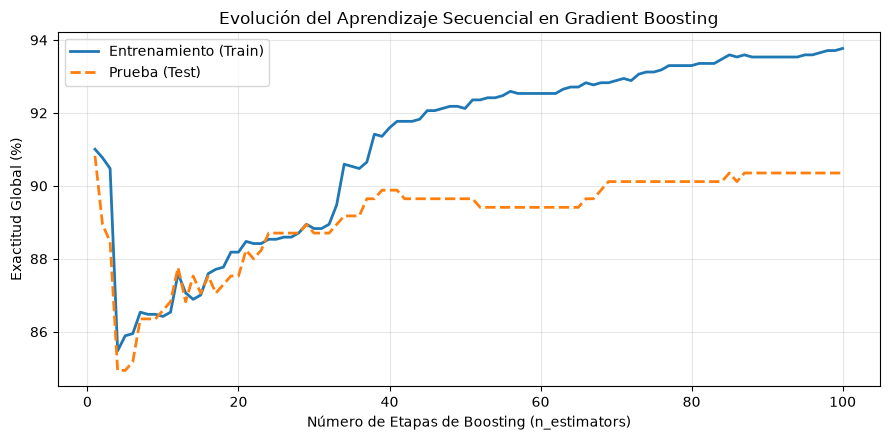

In [5]:
# Graficación por etapa usando staged_predict

# Obtenemos las predicciones paso a paso de cada etapa
train_stages = gb_model.staged_predict(X_train)
test_stages = gb_model.staged_predict(X_test)

# Calculamos la exactitud paso a paso para los datos Train & Test
train_acc_curve = [accuracy(y_train, p) * 100 for p in train_stages]
test_acc_curve = [accuracy(y_test, p) * 100 for p in test_stages]


# Gráfica de evolución
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, n_estimators + 1), train_acc_curve, label='Entrenamiento (Train)', linewidth=2)
plt.plot(range(1, n_estimators + 1), test_acc_curve, label='Prueba (Test)', linewidth=2, linestyle='--')
plt.xlabel('Número de Etapas de Boosting (n_estimators)')
plt.ylabel('Exactitud Global (%)')
plt.title('Evolución del Aprendizaje Secuencial en Gradient Boosting')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Análisis y Conclusiones Finales del Modelo 

El desarrollo de **Gradient Boosting** permitió evaluar cómo influye la ponderación de clases en la clasificación de los registros de salud fetal. En una primera prueba sin balanceo (balanced=False), el modelo alcanzó una Exactitud Global de 93.43%, pero su Recall para la clase Patológica fue de 73.08%. Esto indica que una exactitud elevada, por sí sola, no garantiza una identificación suficiente de los casos de mayor riesgo. Estos resultados corresponden a una prueba previa y no deben compararse directamente con la evaluación actual, debido al cambio en la partición de los datos.

Al incorporar la ponderación de clases (balanced=True), el modelo obtuvo una Exactitud Global de **90.35%** en el conjunto de prueba. Aunque el resultado general no fue el más alto, mejoró la detección de las categorías minoritarias. La evolución observada mediante staged_predict permite analizar cómo cambia el aprendizaje a través de las etapas, utilizando árboles de profundidad 3 y una tasa de aprendizaje de 0.1.

Ya en la evaluación detallada con los datos de prueba, el balanceo mostró el efecto deseado: **se priorizó la sensibilidad en las clases minoritarias**. Las métricas por clase muestran los siguientes resultados:

* **Clase 3 (Patológico):** El *Recall* alcanzó un **94.29%**, acompañado de una Precisión del **82.50%** y un F1-Score de **88.00%**. En la matriz de confusión, de los 35 casos patológicos reales, el modelo detectó correctamente 33, mientras que 2 fueron clasificados en otras categorías.

* **Clase 2 (Sospechoso):** Alcanzó un *Recall* de **84.75%**, identificando correctamente 50 de los 59 registros sospechosos. Su F1-Score fue de **74.07%**, reflejando que todavía existe margen de mejora en la precisión de esta categoría.

* **Clase 1 (Normal):** Obtuvo una Precisión sobresaliente del **97.41%**, con un Recall de **90.94%** y un F1-Score de **94.06%**.

El Promedio Macro F1-Score global se situó en **85.38%**, reflejando un desempeño competitivo, aunque con diferencias entre las tres categorías.

En conclusión, esta comparativa nos deja claro cómo elegir una herramienta según las prioridades médicas. Para un primer filtro experimental donde lo vital es no dejar pasar a ningún paciente de la categoria Patológica, nuestro **Random Forest con Bootstrap balanceado** y este **Gradient Boosting Balanceado** consiguieron el mismo Recall en casos Patológicos (**94.29%**). Sin embargo, Gradient Boosting también presentó un buen Recall en la clase Sospechosa (**84.75%**), aunque con una precisión más baja, por lo que genera un mayor número de falsas alarmas en esta categoría.

---

#### Comparación con modelo de Scikit-learn.

In [6]:
# Modelo de ScikitLearn
from sklearn.ensemble import GradientBoostingClassifier as SklearnGradientBoosting
from sklearn.utils.class_weight import compute_sample_weight # Equivale al balanceo de clases

# Balanceo con sk
sample_weights_sk = compute_sample_weight(class_weight="balanced", y=y_train)

# Ajuste y configuración parecida a nuestro modelo
gb_sklearn = SklearnGradientBoosting(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=0,
)

t0 = time.perf_counter()

gb_sklearn.fit(X_train, y_train, sample_weight=sample_weights_sk)

tiempo_train_sk = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_sk = gb_sklearn.predict(X_test)
tiempo_pred_sk = time.perf_counter() - t0

y_proba_sk = gb_sklearn.predict_proba(X_test)

In [7]:
conf_matrix_sk = confusion_matrix(y_test - 1, y_pred_sk - 1, n_classes=3)
f1s_sk = f1_score(conf_matrix_sk)

# Resultados de rendimiento interno y en prueba
print("--- Rendimiento Gradient Boosting (Scikit-Learn) ---")
print(f"-> Exactitud Global en Entrenamiento: {accuracy(y_train, gb_sklearn.predict(X_train)) * 100:.2f}%")
print(f"-> Exactitud Global en Prueba (Test): {accuracy(y_test, y_pred_sk) * 100:.2f}%")
print(f"-> Tiempo Entrenamiento / Predicción: {tiempo_train_sk:.4f} s / {tiempo_pred_sk:.4f} s")
print(f"-> F1-Score:                    {f1s_sk}")
print(f"-> Recall:                      {recall(conf_matrix_sk)}")
print(f"-> Precision:                   {precision(conf_matrix_sk)}")
print(f"-> Promedio Macro F1-Score:     {np.mean(f1s_sk) * 100:.2f}%")
print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(conf_matrix_sk)

--- Rendimiento Gradient Boosting (Scikit-Learn) ---
-> Exactitud Global en Entrenamiento: 98.77%
-> Exactitud Global en Prueba (Test): 92.24%
-> Tiempo Entrenamiento / Predicción: 1.7168 s / 0.0027 s
-> F1-Score:                    [0.95136778 0.7768595  0.90140845]
-> Recall:                      [0.94561934 0.79661017 0.91428571]
-> Precision:                   [0.95718654 0.75806452 0.88888889]
-> Promedio Macro F1-Score:     87.65%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[313  14   4]
 [ 12  47   0]
 [  2   1  32]]


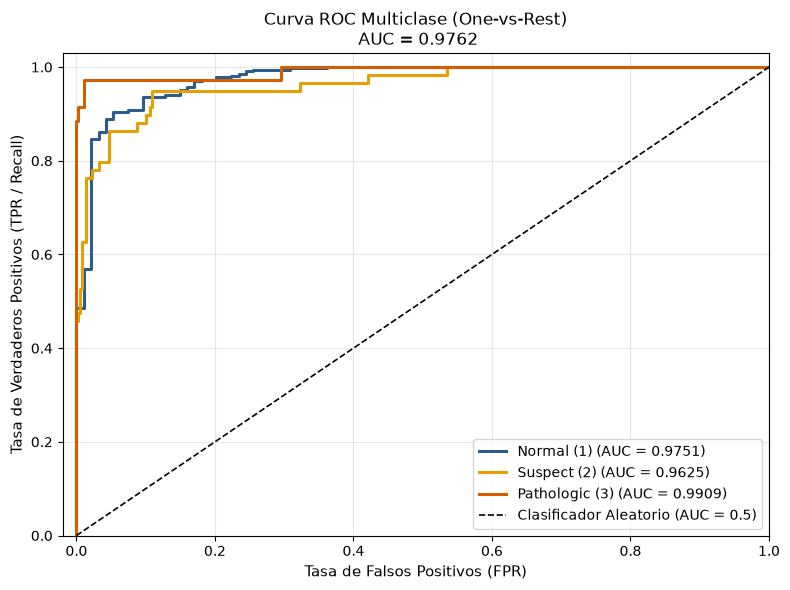

Macro AUC Global (Scikit-Learn): 0.9762


In [8]:
# Modelo Scikit-Learn
macro_auc_sk, aucs_por_clase_sk = roc(gb_sklearn, X_test, y_test)
print(f"Macro AUC Global (Scikit-Learn): {macro_auc_sk:.4f}")

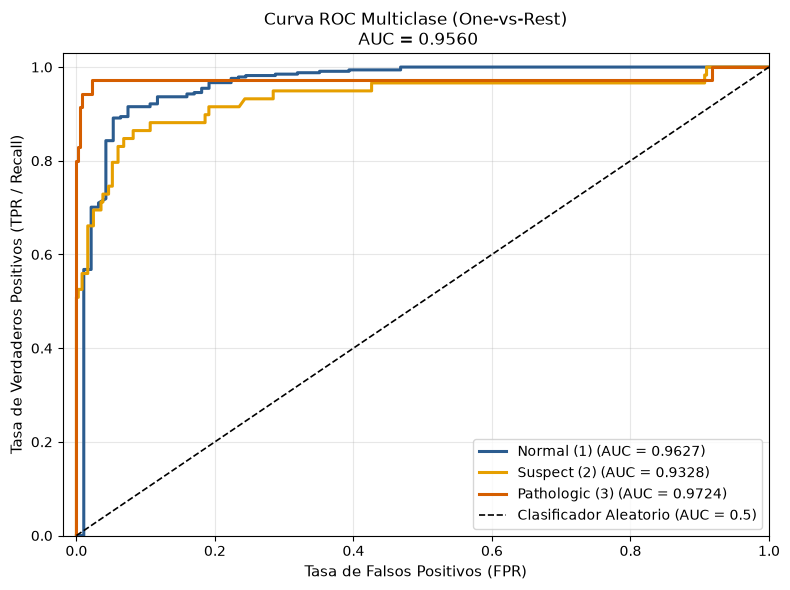

Macro AUC Global (Modelo Propio): 0.9560


In [9]:
# Nuestro Modelo 
macro_auc_gb, aucs_por_clase_gb = roc(gb_model, X_test, y_test)
print(f"Macro AUC Global (Modelo Propio): {macro_auc_gb:.4f}")

#### Conclusión de la Comparativa (Modelo nuestro vs. Scikit-Learn)

Al comparar nuestro Gradient Boosting Balanceado hecho desde cero contra la versión de scikit-learn bajo una configuración similar (n_estimators=100, learning_rate=0.1, max_depth=3) y ponderación de clases, observamos que ambas implementaciones tienen diferencias importantes en su clasificación:

* **Calidad clínica vs. Exactitud global:** scikit-learn logra una exactitud global superior en prueba (**92.24%** vs. **90.35%**) y un mayor Macro AUC (**0.9762** vs. **0.9560**). Sin embargo, nuestro modelo resultó más sensible para detectar las categorías minoritarias: capturó **33 de 35** fetos en estado Patológico (**94.29%** de Recall frente al **91.43%** de scikit-learn) y **50 de 59** Sospechosos (**84.75%** frente al **79.66%**). A pesar de ello, scikit-learn consiguió una mayor Precisión en ambas categorías y un Macro F1-Score superior (**87.65%** frente al **85.38%**).

* **Relación tiempo-calidad:** scikit-learn entrena mucho más rápido (**1.7168 s** frente a **58.7866 s**) gracias a sus implementaciones optimizadas. Durante la predicción también presenta una ventaja considerable (**0.0027 s** frente a **0.1679 s**).

En general, nuestra implementación consigue un Recall superior en las categorías Patológica y Sospechosa dentro de esta evaluación. Sin embargo, la versión de scikit-learn presenta una exactitud global, un Macro F1-Score y una capacidad discriminativa superiores, además de una eficiencia computacional considerablemente mayor.